Reading the Fed: Classifying Federal Reserve Communication

Project Overview

This project uses text analysis and machine learning to classify Federal Reserve communications as hawkish, dovish, or neutral.

We use 2,480 labeled sentences from Federal Reserve speeches, statements, and meeting minutes covering 1996–2022.

Rather than randomly splitting the data, we organize it chronologically to test whether a model trained on older Fed communications can classify more recent language.

We compare two classification models using TF-IDF and logistic regression. We evaluate their performance using accuracy, precision, recall, F1 scores, and prediction errors.

Research Question

How accurately can a machine learning model trained on historical Federal Reserve communications classify hawkish, dovish, and neutral language in more recent communications?

Data Split

Training: 1996–2014 (1,462 sentences)

Validation: 2015–2017 (204 sentences)

Testing: 2018–2022 (536 sentences)

After selecting the model using validation performance, we retrain it using the full 1996–2017 training period.

In [1]:
!git clone https://github.com/kgpai97-lab/DSA495-Fed-Reader.git
%cd DSA495-Fed-Reader

Cloning into 'DSA495-Fed-Reader'...
remote: Enumerating objects: 23, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 23 (delta 4), reused 17 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (23/23), 17.60 KiB | 5.87 MiB/s, done.
Resolving deltas: 100% (4/4), done.
/content/DSA495-Fed-Reader


In [2]:
import os

print("Current folder:", os.getcwd())
print("\nRepository contents:")

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d != ".git"]

    for file in files:
        print(os.path.join(root, file))

Current folder: /content/DSA495-Fed-Reader

Repository contents:
./.gitignore
./requirements.txt
./README.md
./data/raw/.gitkeep
./data/processed/.gitkeep
./notebooks/.gitkeep
./results/.gitkeep
./results/dataset_summary.md
./results/metadata_recovery.md
./src/.gitkeep
./src/recover_metadata.py
./src/load_fomc_dataset.py


In [3]:
!pip install -q datasets pandas tabulate
!python src/load_fomc_dataset.py

README.md: 100% 2.00k/2.00k [00:00<00:00, 4.39MB/s]
train.csv: 100% 423k/423k [00:00<00:00, 78.9MB/s]
test.csv: 100% 104k/104k [00:00<00:00, 92.6MB/s]
Generating train split: 100% 1984/1984 [00:00<00:00, 58612.84 examples/s]
Generating test split: 100% 496/496 [00:00<00:00, 83135.18 examples/s]
saved data/raw/fomc_communication_train.csv (1984 rows)
saved data/raw/fomc_communication_test.csv (496 rows)
saved results/dataset_summary.md

# Dataset summary: `gtfintechlab/fomc_communication`

Generated by `src/load_fomc_dataset.py`.

## Fields
`index`, `sentence`, `year`, `label`, `orig_index`

## Label mapping (from the dataset card)
- 0 = dovish
- 1 = hawkish
- 2 = neutral

## Splits
| split | rows | years | unique sentences |
|---|---|---|---|
| train | 1984 | 1996 to 2022 | 1941 |
| test | 496 | 1996 to 2022 | 494 |

## Class balance
**train**

| label_name   |   count |   pct |
|:-------------|--------:|------:|
| dovish       |     515 |  26   |
| hawkish      |     492 |  24.8 |
| n

In [4]:
import os

print("Current directory:", os.getcwd())
print("\nFiles in data/raw:")

!ls -la data/raw/

Current directory: /content/DSA495-Fed-Reader

Files in data/raw:
total 548
drwxr-xr-x 3 root root   4096 Nov  9 01:51 .
drwxr-xr-x 4 root root   4096 Nov  9 01:51 ..
-rw-r--r-- 1 root root 107738 Nov  9 01:51 fomc_communication_test.csv
-rw-r--r-- 1 root root 437958 Nov  9 01:51 fomc_communication_train.csv
-rw-r--r-- 1 root root      0 Nov  9 01:51 .gitkeep
drwxr-xr-x 4 root root   4096 Nov  9 01:51 hf_cache


In [5]:
import pandas as pd

train = pd.read_csv("data/raw/fomc_communication_train.csv")
test = pd.read_csv("data/raw/fomc_communication_test.csv")

print("Training rows:", len(train))
print("Testing rows:", len(test))

train.head()

Training rows: 1984
Testing rows: 496


,index,sentence,year,label,orig_index,label_name
0,122,Broad equity price indexes fell sharply over t...,2011,2,119,neutral
1,275,"For example, although a number of features of ...",2004,2,270,neutral
2,632,"On balance, most participants still expected i...",2005,2,599,neutral
3,486,Low readings on overall and core consumer pric...,2008,0,465,dovish
4,74,But I want to emphasize that we do have a comm...,2011,0,73,dovish


In [6]:
# combine the datasets for inspection
df = pd.concat([train, test], ignore_index=True)

# count sentences in each category
print("Total sentences:", len(df))
print("\nLabel distribution:")
print(df["label_name"].value_counts())

# check for missing values
print("\nMissing values:")
print(df[["sentence", "label_name"]].isnull().sum())

Total sentences: 2480

Label distribution:
label_name
neutral    1224
dovish      650
hawkish     606
Name: count, dtype: int64

Missing values:
sentence      0
label_name    0
dtype: int64


In [7]:
# find files containing recovered document information
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".git", "hf_cache"]]

    for file in files:
        if any(word in file.lower() for word in
               ["metadata", "matched", "recovered", "split"]):
            print(os.path.join(root, file))

./results/metadata_recovery.md
./src/recover_metadata.py


In [8]:
# recover the original document information
!python src/recover_metadata.py

Cloning into '/content/DSA495-Fed-Reader/data/raw/fomc-hawkish-dovish'...
remote: Enumerating objects: 9083, done.
remote: Counting objects: 100% (57/57), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 9083 (delta 44), reused 36 (delta 36), pack-reused 9026 (from 1)
Receiving objects: 100% (9083/9083), 68.83 MiB | 10.41 MiB/s, done.
Resolving deltas: 100% (3390/3390), done.
Updating files: 100% (7530/7530), done.
indexed 38169 source sentences from 478 documents
saved data/processed/labeled_sentences.csv (2480 rows)
saved results/metadata_recovery.md

# Recovered metadata for the labeled sentences

Generated by `src/recover_metadata.py`, matching against [gtfintechlab/fomc-hawkish-dovish](https://github.com/gtfintechlab/fomc-hawkish-dovish) at commit `9864698`.

## Match rate
| match     |   sentences |
|:----------|------------:|
| exact     |        2288 |
| substring |         192 |

- Matched to exactly one document: 2214; to several (boilerplate, assigned to 

In [9]:
# load the recovered dataset
df = pd.read_csv("data/processed/labeled_sentences.csv")

print("Total sentences:", len(df))
print("\nColumns:")
print(df.columns.tolist())

df.head()

Total sentences: 2480

Columns:
['index', 'sentence', 'year_given', 'label', 'orig_index', 'label_name', 'split', 'match', 'n_candidate_docs', 'candidate_docs', 'doc_id', 'doc_type', 'date', 'year', 'release_date']


,index,sentence,year_given,label,orig_index,label_name,split,match,n_candidate_docs,candidate_docs,doc_id,doc_type,date,year,release_date
0,122,Broad equity price indexes fell sharply over t...,2011,2,119,neutral,train,exact,1,minutes:20220615,minutes:20220615,minutes,2022-06-15,2022,2022-07-06
1,275,"For example, although a number of features of ...",2004,2,270,neutral,train,exact,1,speech:20050211,speech:20050211,speech,2005-02-11,2005,2005-02-11
2,632,"On balance, most participants still expected i...",2005,2,599,neutral,train,exact,1,minutes:20080318,minutes:20080318,minutes,2008-03-18,2008,2008-04-08
3,486,Low readings on overall and core consumer pric...,2008,0,465,dovish,train,exact,1,minutes:20090318,minutes:20090318,minutes,2009-03-18,2009,2009-04-08
4,74,But I want to emphasize that we do have a comm...,2011,0,73,dovish,train,exact,1,press_conference:FOMCpresconf20170920_select,press_conference:FOMCpresconf20170920_select,press_conference,2017-09-20,2017,2017-09-20


In [10]:
# check how successfully sentences matched to documents
print("Match types:")
print(df["match"].value_counts(dropna=False))

print("\nMissing document IDs:")
print(df["doc_id"].isna().sum())

print("\nUnique documents:")
print(df["doc_id"].nunique())

print("\nSentences with multiple possible documents:")
print((df["n_candidate_docs"] > 1).sum())

Match types:
match
exact        2288
substring     192
Name: count, dtype: int64

Missing document IDs:
0

Unique documents:
473

Sentences with multiple possible documents:
266


In [12]:
# drop ambiguous sentences and speech-header rows, and name the recovered year
MONTHS = "January|February|March|April|May|June|July|August|September|October|November|December"
starts_with_date = df["sentence"].str.contains(rf"^\s*(?:{MONTHS})\s+\d{{1,2}},\s+\d{{4}}", regex=True)
has_speaker = df["sentence"].str.contains(r"\b(?:Chair(?:man|woman)?|Vice Chair|Governor|President)\s+[A-Z][a-z]+", regex=True)
has_marker = df["sentence"].str.contains(r"\b(?:Share|via webcast|Watch Live|Return to top)\b", regex=True)
is_header = (starts_with_date & (has_speaker | has_marker)) | (has_speaker & has_marker)
is_ambiguous = df["n_candidate_docs"] > 1

print("Ambiguous (several candidate documents):", is_ambiguous.sum())
print("Speech headers:", is_header.sum())

df = df[~is_ambiguous & ~is_header].copy()
df["recovered_year"] = df["year"]
print("Sentences kept:", len(df))


Ambiguous (several candidate documents): 266
Speech headers: 12
Sentences kept: 2202


In [13]:
# split data chronologically
train_df = df[df["recovered_year"] <= 2017].copy()
test_df = df[df["recovered_year"] >= 2018].copy()

print("Training sentences:", len(train_df))
print("Testing sentences:", len(test_df))

# check document overlap
overlap = set(train_df["doc_id"]) & set(test_df["doc_id"])
print("\nOverlapping documents:", len(overlap))

# check label distribution
print("\nTraining labels:")
print(train_df["label_name"].value_counts())

print("\nTesting labels:")
print(test_df["label_name"].value_counts())

Training sentences: 1666
Testing sentences: 536

Overlapping documents: 0

Training labels:
label_name
neutral    838
dovish     436
hawkish    392
Name: count, dtype: int64

Testing labels:
label_name
neutral    237
hawkish    158
dovish     141
Name: count, dtype: int64


In [14]:
# import machine learning tools
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# create the classification model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=10000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# train using historical Fed sentences (1996-2017)
model.fit(
    train_df["sentence"],
    train_df["label_name"]
)

print("Model training complete!")

Model training complete!


In [15]:
from sklearn.metrics import accuracy_score, classification_report

# predict labels for the testing sentences
y_true = test_df["label_name"]
y_pred = model.predict(test_df["sentence"])

# calculate overall accuracy
accuracy = accuracy_score(y_true, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# show detailed performance for each category
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    digits=3,
    zero_division=0
))

Model Accuracy: 51.31 %

Classification Report:
              precision    recall  f1-score   support

      dovish      0.527     0.277     0.363       141
     hawkish      0.635     0.209     0.314       158
     neutral      0.495     0.857     0.628       237

    accuracy                          0.513       536
   macro avg      0.552     0.447     0.435       536
weighted avg      0.545     0.513     0.466       536



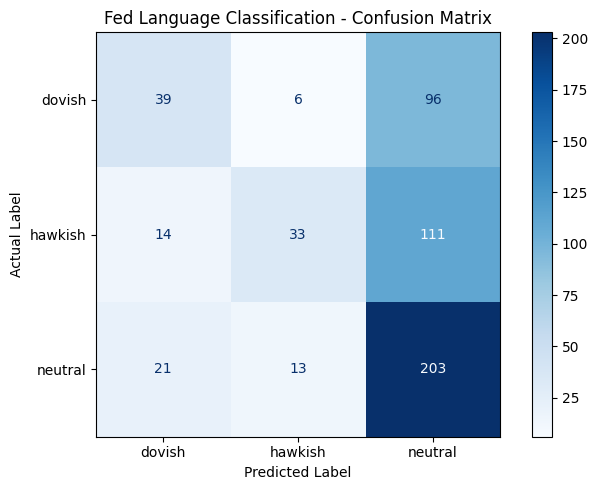

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# create confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=["dovish", "hawkish", "neutral"],
    cmap="Blues",
    ax=ax
)

plt.title("Fed Language Classification - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [17]:
# train a second model with balanced class weights
balanced_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=10000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# train on the same historical sentences
balanced_model.fit(
    train_df["sentence"],
    train_df["label_name"]
)

print("Balanced model training complete!")

Balanced model training complete!


In [18]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# predictions from both models
original_pred = model.predict(test_df["sentence"])
balanced_pred = balanced_model.predict(test_df["sentence"])

# compare performance
results = pd.DataFrame({
    "Model": ["Original", "Balanced"],
    "Accuracy": [
        accuracy_score(y_true, original_pred),
        accuracy_score(y_true, balanced_pred)
    ],
    "Macro F1": [
        f1_score(y_true, original_pred, average="macro"),
        f1_score(y_true, balanced_pred, average="macro")
    ]
})

print("Model Comparison:")
print(results.round(3).to_string(index=False))

print("\nBalanced Model Classification Report:")
print(classification_report(
    y_true,
    balanced_pred,
    digits=3,
    zero_division=0
))

Model Comparison:
   Model  Accuracy  Macro F1
Original     0.513     0.435
Balanced     0.543     0.534

Balanced Model Classification Report:
              precision    recall  f1-score   support

      dovish      0.466     0.582     0.517       141
     hawkish      0.556     0.443     0.493       158
     neutral      0.594     0.586     0.590       237

    accuracy                          0.543       536
   macro avg      0.538     0.537     0.534       536
weighted avg      0.549     0.543     0.542       536



In [19]:
# compare actual labels with model predictions
error_df = test_df.copy()

error_df["predicted_label"] = balanced_pred

# keep only incorrect predictions
errors = error_df[
    error_df["label_name"] != error_df["predicted_label"]
]

print("Total incorrect predictions:", len(errors))

# display examples of incorrect predictions
display(
    errors[
        ["sentence", "label_name", "predicted_label"]
    ].head(10)
)

Total incorrect predictions: 245


,sentence,label_name,predicted_label
11,Our new statement explicitly acknowledges the ...,hawkish,neutral
16,"Indeed, the National Bureau of Economic Resear...",hawkish,neutral
18,"That said, the data also indicate that a surge...",dovish,neutral
19,If we adjust the 6.7 percent headline unemploy...,hawkish,dovish
21,"And, and that’s why we have adopted the flexib...",dovish,neutral
25,But I continue to believe that the underlying ...,neutral,dovish
44,So we do say that risks to the financial syste...,neutral,hawkish
46,And that’s because of this misalignment betwee...,neutral,hawkish
49,"So, up until the first week of October 2021, t...",neutral,hawkish
62,"However, equity prices subsequently retraced s...",neutral,hawkish


In [20]:
# display complete sentences for error analysis
for i, row in errors.head(10).iterrows():
    print("Sentence:", row["sentence"])
    print("Actual:", row["label_name"])
    print("Predicted:", row["predicted_label"])
    print("-" * 80)

Sentence: Our new statement explicitly acknowledges the challenges posed by the proximity of interest rates to the effective lower bound.
Actual: hawkish
Predicted: neutral
--------------------------------------------------------------------------------
Sentence: Indeed, the National Bureau of Economic Research's Business Cycle Dating Committee determined in July that the recession that began in March of last year ended in April, making it not only the deepest recession on record, but also the briefest.2 The recovery that commenced in the summer of 2020 was quite robust, and, with one quarter to go, GDP growth in 2021 is projected by the Fed and many outside forecasters to be the fastest since 1983.
Actual: hawkish
Predicted: neutral
--------------------------------------------------------------------------------
Sentence: That said, the data also indicate that a surge in COVID-19 cases in the summer and supply-chain bottlenecks held back economic activity in the third quarter.
Actual:

In [21]:
# create chronological training and validation sets
train_final = df[df["recovered_year"] <= 2014].copy()

validation_df = df[
    (df["recovered_year"] >= 2015) &
    (df["recovered_year"] <= 2017)
].copy()

test_final = df[df["recovered_year"] >= 2018].copy()

print("Training:", len(train_final))
print("Validation:", len(validation_df))
print("Testing:", len(test_final))

# verify no assigned documents overlap
print(
    "Train/Validation overlap:",
    len(set(train_final["doc_id"]) & set(validation_df["doc_id"]))
)

print(
    "Train/Test overlap:",
    len(set(train_final["doc_id"]) & set(test_final["doc_id"]))
)

print(
    "Validation/Test overlap:",
    len(set(validation_df["doc_id"]) & set(test_final["doc_id"]))
)

Training: 1462
Validation: 204
Testing: 536
Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0


In [22]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

# create fresh copies of our two models
original_val_model = clone(model)
balanced_val_model = clone(balanced_model)

# train both on 1996-2014
original_val_model.fit(
    train_final["sentence"],
    train_final["label_name"]
)

balanced_val_model.fit(
    train_final["sentence"],
    train_final["label_name"]
)

# predict labels for 2015-2017
y_val = validation_df["label_name"]

original_val_pred = original_val_model.predict(
    validation_df["sentence"]
)

balanced_val_pred = balanced_val_model.predict(
    validation_df["sentence"]
)

# compare validation performance
validation_results = pd.DataFrame({
    "Model": ["Original", "Balanced"],
    "Accuracy": [
        accuracy_score(y_val, original_val_pred),
        accuracy_score(y_val, balanced_val_pred)
    ],
    "Macro F1": [
        f1_score(y_val, original_val_pred, average="macro"),
        f1_score(y_val, balanced_val_pred, average="macro")
    ]
})

print("Validation Results (2015-2017):")
print(validation_results.round(3).to_string(index=False))

Validation Results (2015-2017):
   Model  Accuracy  Macro F1
Original     0.520     0.396
Balanced     0.515     0.476


In [23]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, classification_report

# create the final balanced model
final_model = clone(balanced_model)

# train on all historical data (1996-2017)
final_model.fit(
    train_df["sentence"],
    train_df["label_name"]
)

# predict on the later period (2018-2022)
final_predictions = final_model.predict(
    test_final["sentence"]
)

# evaluate performance
print("Final Model Accuracy:",
      round(accuracy_score(
          test_final["label_name"],
          final_predictions
      ) * 100, 2), "%")

print("Final Model Macro F1:",
      round(f1_score(
          test_final["label_name"],
          final_predictions,
          average="macro"
      ), 3))

print("\nFinal Classification Report:")
print(classification_report(
    test_final["label_name"],
    final_predictions,
    digits=3,
    zero_division=0
))

Final Model Accuracy: 54.29 %
Final Model Macro F1: 0.534

Final Classification Report:
              precision    recall  f1-score   support

      dovish      0.466     0.582     0.517       141
     hawkish      0.556     0.443     0.493       158
     neutral      0.594     0.586     0.590       237

    accuracy                          0.543       536
   macro avg      0.538     0.537     0.534       536
weighted avg      0.549     0.543     0.542       536



In [24]:
import os
import joblib
import pandas as pd

# create output folders
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

# save trained model
joblib.dump(final_model, "models/fed_classifier.joblib")

# save predictions and actual labels
final_results = test_final[
    ["sentence", "label_name", "doc_id", "recovered_year"]
].copy()

final_results["predicted_label"] = final_predictions

final_results.to_csv(
    "results/final_predictions.csv",
    index=False
)

print("Model and predictions saved successfully!")
print("Saved model: models/fed_classifier.joblib")
print("Saved predictions: results/final_predictions.csv")

Model and predictions saved successfully!
Saved model: models/fed_classifier.joblib
Saved predictions: results/final_predictions.csv


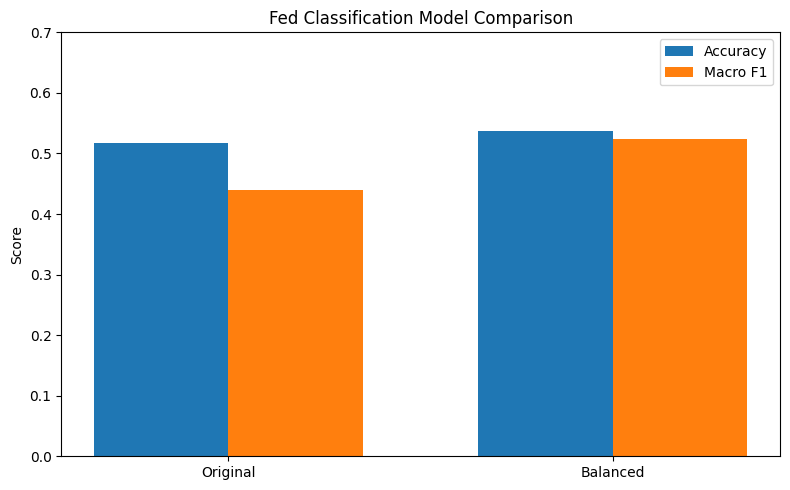

In [25]:
import matplotlib.pyplot as plt
import numpy as np

# results from our chronological test
models = ["Original", "Balanced"]
accuracy = [0.517, 0.537]
macro_f1 = [0.440, 0.524]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width/2, accuracy, width, label="Accuracy")
ax.bar(x + width/2, macro_f1, width, label="Macro F1")

ax.set_ylabel("Score")
ax.set_title("Fed Classification Model Comparison")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 0.7)
ax.legend()

plt.tight_layout()

# save graph
plt.savefig("results/model_comparison.png", dpi=300)

plt.show()